In [1]:
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
df = pd.read_csv("Sample - Superstore.csv", encoding="latin1")

print("First 5 Rows:")
display(df.head())

print("\nDataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

First 5 Rows:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164



Dataset Shape: (9994, 21)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   objec

In [3]:
df.columns = df.columns.str.strip()

df = df.dropna(subset=["Region", "Category", "Sales"])

print(df[["Region", "Category", "Sales"]].head())

  Region         Category     Sales
0  South        Furniture  261.9600
1  South        Furniture  731.9400
2   West  Office Supplies   14.6200
3  South        Furniture  957.5775
4  South  Office Supplies   22.3680


In [4]:
region_sales = df.groupby("Region")["Sales"].sum()

print("Total Sales by Region:")
print(region_sales)

Total Sales by Region:
Region
Central    501239.8908
East       678781.2400
South      391721.9050
West       725457.8245
Name: Sales, dtype: float64


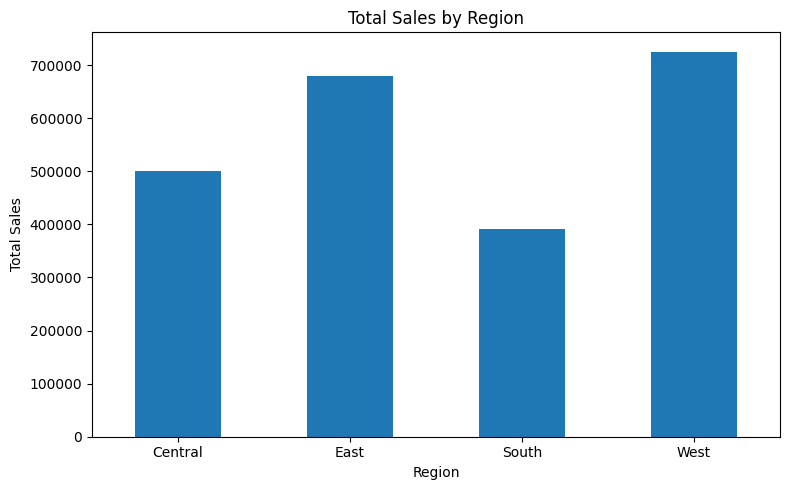

In [5]:
region_sales.plot(kind="bar", figsize=(8, 5))

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [6]:
top_region = region_sales.idxmax()
highest_sales = region_sales.max()

print("Top Performing Region:", top_region)
print("Highest Total Sales:", round(highest_sales, 2))

Top Performing Region: West
Highest Total Sales: 725457.82


In [7]:
category_sales = pd.pivot_table(
    df,
    index="Region",
    columns="Category",
    values="Sales",
    aggfunc="sum",
    fill_value=0
)

print("Sales by Region and Product Category:")
display(category_sales)

Sales by Region and Product Category:


Category,Furniture,Office Supplies,Technology
Region,,,
Central,163797.1638,167026.415,170416.312
East,208291.2040,205516.055,264973.981
South,117298.6840,125651.313,148771.908
West,252612.7435,220853.249,251991.832


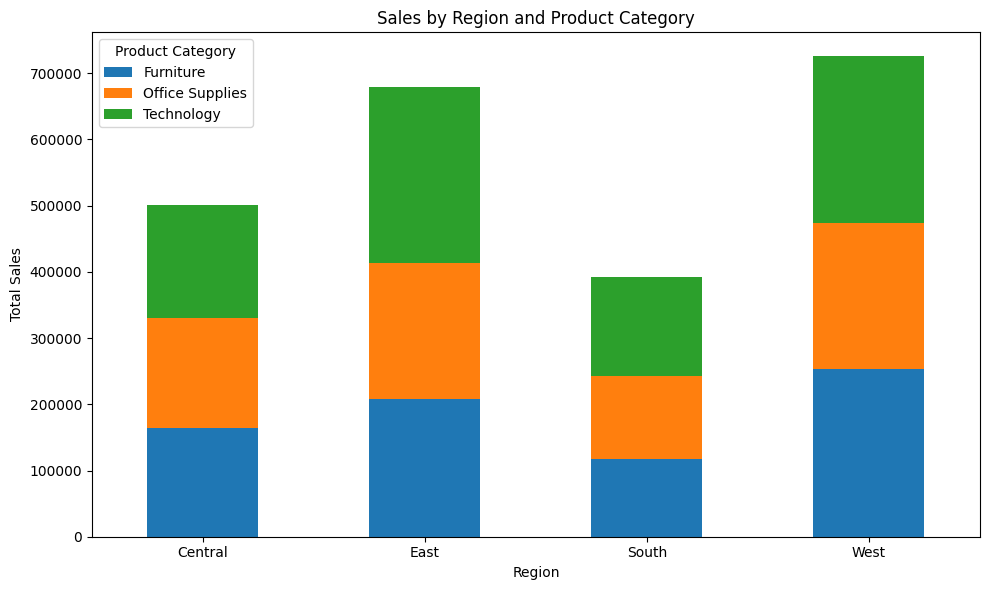

In [8]:
category_sales.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Sales by Region and Product Category")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.legend(title="Product Category")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

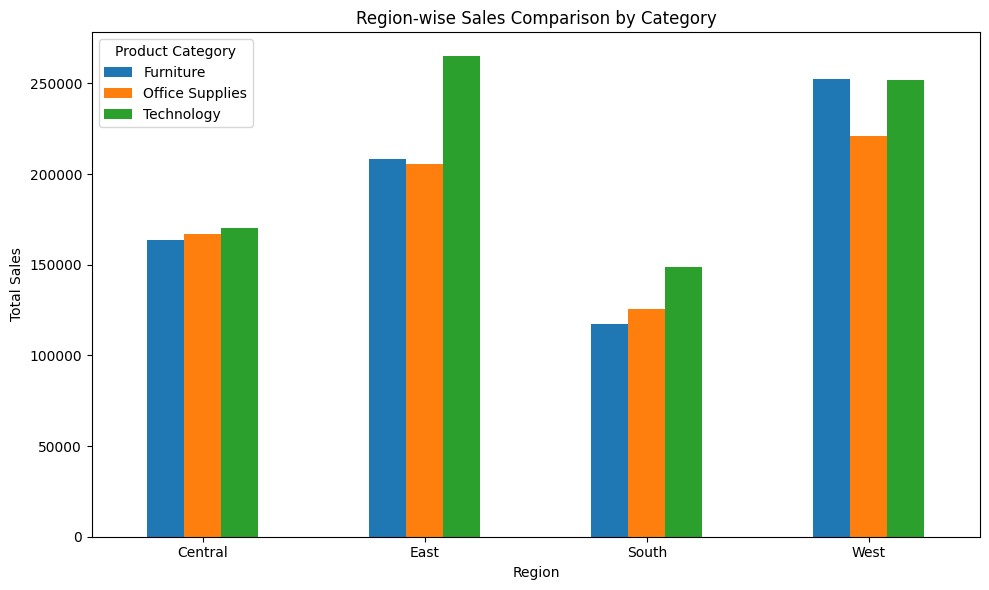

In [10]:
category_sales.plot(
    kind="bar",
    stacked=False,
    figsize=(10, 6)
)

plt.title("Region-wise Sales Comparison by Category")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.legend(title="Product Category")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
region_sales.to_csv("Total_Sales_by_Region.csv")
category_sales.to_csv("Sales_by_Region_and_Category.csv")

print("Data Aggregation Completed Successfully!")

Data Aggregation Completed Successfully!
